# Forelesning 2: Datahåndtering med Pandas

<div class="bilde-midt" style="width:32%">

![Panda](bilder/panda.jpg)
<p class="kreditering">Foto: <a href="https://commons.wikimedia.org/wiki/File:A_picture_of_a_Panda.jpg">George Lu</a>, <a href="https://creativecommons.org/licenses/by/2.0/">CC BY 2.0</a>, via Wikimedia Commons</p>

</div>

I denne forelesningen skal vi:

- lage enkle, gode figurer av kjemiske måledata med Matplotlib
- lese datafiler med Pandas og undersøke hva vi faktisk har lest
- håndtere manglende verdier uten å ødelegge rådataene
- filtrere, sortere og gruppere data
- lage nye kolonner, for eksempel blankkorrigert absorbans
- gå fra dataramme til figur

<div class="bilde-hoyre" style="width:34%">

![UV-Vis-spektrofotometer](bilder/spektrofotometer.jpg)
<p class="kreditering">Foto: <a href="https://commons.wikimedia.org/wiki/File:Spektrofotometers_bild.jpg">Ejaz S</a>, <a href="https://creativecommons.org/licenses/by/2.0/">CC BY 2.0</a>, via Wikimedia Commons</p>

</div>

Gjennomgangseksempelet er et UV-Vis-forsøk med blankprøver, kalibreringsstandarder og tre replikater av en ukjent prøve. Seinere i emnet skal vi bruke standardene til å bestemme konsentrasjonen i den ukjente prøven. I dag gjør vi dataene klare for det.

In [ ]:
import matplotlib.pyplot as plt

# Større figurer og skrift, slik at plottene er lesbare på lysbildene
plt.rcParams.update({"font.size": 14, "figure.figsize": (8, 4.5)})

## Del 1: Gode kjemiske figurer

<div class="viktig">

Før vi lager en figur, bør vi spørre:

- Hva representerer hvert datapunkt?
- Hvilken variabel har vi kontrollert, og hvilken har vi målt?
- Følger punktene en naturlig rekkefølge, for eksempel i tid?

</div>

Damptrykket til vann er målt ved fem temperaturer. Temperaturen er valgt, og damptrykket er målt.

| Temperatur (°C) | 16 | 18 | 20 | 22 | 24 |
|---|---|---|---|---|---|
| Damptrykk (kPa) | 1,817 | 2,063 | 2,339 | 2,644 | 2,984 |

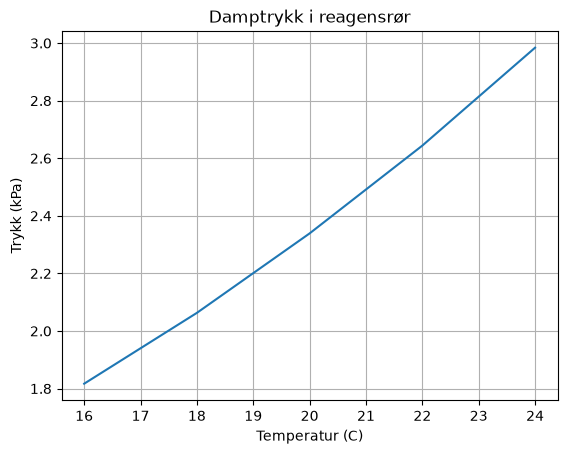

In [24]:
import matplotlib.pyplot as plt

temp_C = [16, 18, 20, 22, 24]
trykk_kPa = [1.817, 2.063, 2.339, 2.644, 2.984]

plt.plot(temp_C, trykk_kPa)
plt.xlabel("Temperatur (C)")
plt.ylabel("Trykk (kPa)")
plt.title("Damptrykk i reagensrør")
plt.grid()
plt.show()

### Skal punktene bindes sammen?

<div class="viktig">

Bruk **punktplott** (`scatter`) for enkeltmålinger og sammenhenger mellom to størrelser. Bruk **linjer** (`plot`) når rekkefølgen er viktig, for eksempel i en tidsserie, eller når linja er en modell. En linje mellom målepunkter betyr ikke at vi har målt verdiene mellom punktene.

</div>

Absorbansen er målt gjennom en reaksjon ved to temperaturer.

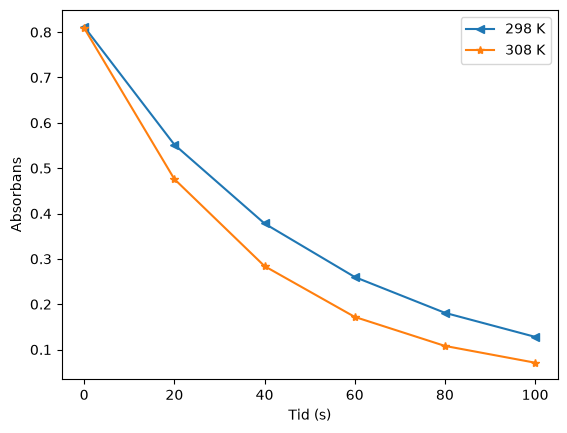

In [30]:
time_s = [0, 20, 40, 60, 80, 100]
absorbance_298_K = [0.812, 0.552, 0.378, 0.260, 0.181, 0.128]
absorbance_308_K = [0.809, 0.476, 0.284, 0.172, 0.108, 0.071]

plt.plot(time_s, absorbance_298_K, marker = "<", label = "298 K")
plt.plot(time_s, absorbance_308_K, marker = "*", label = "308 K")
plt.xlabel("Tid (s)")
plt.ylabel("Absorbans")
plt.legend()
plt.show()

<div class="diskuter">

**Diskuter:** Hvilken blanding reagerer raskest? Er figuren alene nok til å konkludere med at temperaturen er årsaken?

</div>

<div class="oppgave">

**Prøv selv:** Programmet nedenfor lager en figur som er vanskelig å tolke. Anta at `x` er tid i timer og `y` er pH. Finn minst fire forbedringer.
</div>

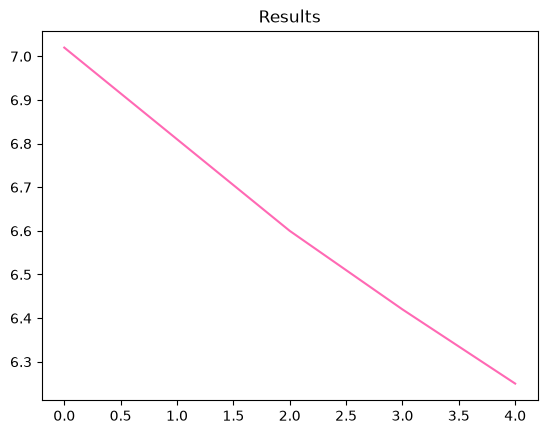

In [35]:
tid_timer = [0, 1, 2, 3, 4]
pH = [7.02, 6.81, 6.60, 6.42, 6.25]

plt.plot(tid_timer, pH, color="hotpink")
plt.title("Results")
plt.show()

## Del 2: Datafiler

Store datasett skriver vi ikke inn i lister for hånd. De ligger i datafiler, ofte som CSV (*comma-separated values*). Her er starten av fila `uvvis_raw.csv`, som råtekst og slik Pandas leser den:

<div class="bilde-midt" style="width:95%">

![CSV som råtekst og som dataramme](bilder/csv_og_dataramme.png)

</div>

<div class="viktig">

**Ryddig dataformat:** Hver rad er én observasjon, hver kolonne er én variabel, og hver celle inneholder én verdi. Enheten står i kolonnenavnet (`concentration_uM`), mens cellene bare inneholder tall.

</div>

<div class="diskuter">

**Diskuter:** Hvorfor er det dårlig å skrive `"2 µmol/L"` i cellene i stedet for `2`?

</div>

## Del 3: Lese og undersøke data

Pandas leser tabelldata og gir oss en *dataramme* (`DataFrame`).

<div class="viktig">

En **dataramme** er en tabell med navngitte kolonner og rader. I motsetning til en tabell i et regneark kan vi behandle hele kolonner med kode.

</div>

Notatboka ligger i mappa `forelesninger`, mens datafilene ligger i `datahandtering_visualisering/data`. `..` betyr «gå én mappe opp».

In [37]:
import pandas as pd

In [44]:
raw_data = pd.read_csv("../datahandtering_visualisering/data/uvvis_raw.csv")

In [45]:
raw_data

,sample_id,sample_type,concentration_uM,replicate,absorbance
0,blank_1,blank,0.0,1,0.010
1,blank_2,blank,0.0,2,0.011
2,std_2_1,standard,2.0,1,0.171
3,std_2_2,standard,2.0,2,0.169
4,std_2_3,standard,2.0,3,0.172
5,std_4_1,standard,4.0,1,0.329
6,std_4_2,standard,4.0,2,0.331
7,std_4_3,standard,4.0,3,0.328
8,std_6_1,standard,6.0,1,0.489
9,std_6_2,standard,6.0,2,0.491


### Hva har vi egentlig lest?
Før vi analyserer noe, sjekker vi hva Pandas har lest.

| Kode | Gir |
|---|---|
| `raw_data.head()` / `raw_data.tail()` | de fem første / siste radene |
| `raw_data.shape` | antall rader og kolonner |
| `raw_data.columns` | kolonnenavnene |
| `raw_data.dtypes` | datatypen til hver kolonne |
| `raw_data.info()` | alt dette samlet, pluss antall verdier som ikke mangler |

In [51]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sample_id         20 non-null     str    
 1   sample_type       20 non-null     str    
 2   concentration_uM  17 non-null     float64
 3   replicate         20 non-null     int64  
 4   absorbance        19 non-null     float64
dtypes: float64(2), int64(1), str(2)
memory usage: 932.0 bytes


<div class="diskuter">

**Diskuter:** Konsentrasjonen mangler for den ukjente prøven. Er det en feil? Hvor finner du den andre manglende verdien, og er den en feil?

</div>

### Kolonner
En kolonne hentes med navnet i hakeparenteser. Resultatet er en *serie*, og den har metoder for vanlige beregninger.

In [58]:
konsentrasjon = raw_data["concentration_uM"] # Serie
absorbans = raw_data["absorbance"]

print(absorbans.max())
print(absorbans.std())

0.812
0.26300366884239734


<div class="oppgave">

**Prøv selv:** Fila `example_semicolon.csv` er lagret slik norske regneark ofte gjør det: med semikolon som skilletegn og komma som desimaltegn. Kjør koden. Hva har gått galt? Rett den opp med argumentene `sep` og `decimal` i `read_csv`, slik at konsentrasjonen blir tall.

</div>

In [ ]:
semicolon_data = pd.read_csv("../datahandtering_visualisering/data/example_semicolon.csv")
print(semicolon_data)
print(semicolon_data.dtypes)

## Del 4: Rydde data

<div class="viktig">

**Bevar rådataene.** Vi endrer aldri `raw_data`. Alle ryddevalg gjøres på en kopi, og koden dokumenterer hva vi har gjort:

1. `raw_data`: dataene slik de ble lest
2. `clean_data = raw_data.copy()`: kopien vi rydder i
3. Analysen gjøres på `clean_data`

</div>

### Manglende verdier
Pandas markerer manglende verdier som `NaN` (*not a number*).

In [60]:
print(raw_data.isna().sum())

sample_id           0
sample_type         0
concentration_uM    3
replicate           0
absorbance          1
dtype: int64


In [62]:
clean_data = raw_data.copy()
clean_data = clean_data.dropna(subset=["absorbance"])
clean_data


,sample_id,sample_type,concentration_uM,replicate,absorbance
0,blank_1,blank,0.0,1,0.010
1,blank_2,blank,0.0,2,0.011
2,std_2_1,standard,2.0,1,0.171
3,std_2_2,standard,2.0,2,0.169
4,std_2_3,standard,2.0,3,0.172
5,std_4_1,standard,4.0,1,0.329
6,std_4_2,standard,4.0,2,0.331
7,std_4_3,standard,4.0,3,0.328
8,std_6_1,standard,6.0,1,0.489
9,std_6_2,standard,6.0,2,0.491


<div class="viktig">

`NaN` og `0` er ikke det samme. Null kan være et gyldig måleresultat, mens `NaN` betyr at verdien ikke finnes. Det finnes ingen automatisk riktig måte å håndtere en manglende verdi på. Valget må begrunnes faglig.

</div>

I instrumentloggen står det at målingen `std_6_3` mislyktes fordi kyvetten sto feil. Det er en god grunn til å utelate akkurat denne raden.

<div class="oppgave">

**Prøv selv:** Tipp først: Hva skjer hvis vi bruker `dropna()` *uten* argumenter på hele datasettet? Kjør koden og se om du hadde rett. Bruk deretter `subset` slik at bare raden med manglende absorbans fjernes.

</div>

In [ ]:
print(raw_data.dropna())

clean_data = raw_data.copy()
clean_data = clean_data.dropna(??)
print(clean_data.shape)

## Del 5: Filtrere, sortere og gruppere

Et logisk vilkår på en kolonne gir en serie med `True` og `False`. Når vi bruker serien inne i hakeparentesene, beholdes bare radene der svaret er `True`.

In [63]:
standardløsninger = clean_data[clean_data["sample_type"] == "standard"]
ukjente = clean_data[clean_data["sample_type"] == "unknown"]
kjente = clean_data[clean_data["sample_type"] != "unknown"]

,sample_id,sample_type,concentration_uM,replicate,absorbance
2,std_2_1,standard,2.0,1,0.171
3,std_2_2,standard,2.0,2,0.169
4,std_2_3,standard,2.0,3,0.172
5,std_4_1,standard,4.0,1,0.329
6,std_4_2,standard,4.0,2,0.331
7,std_4_3,standard,4.0,3,0.328
8,std_6_1,standard,6.0,1,0.489
9,std_6_2,standard,6.0,2,0.491
11,std_8_1,standard,8.0,1,0.648
12,std_8_2,standard,8.0,2,0.652


Flere vilkår kombineres med `&` (og), `|` (eller) og `~` (ikke). **Hvert vilkår må stå i parentes.**

```python
selected = clean_data[
    (clean_data["sample_type"] == "standard")
    & (clean_data["concentration_uM"] >= 4)
]
```

<div class="oppgave">

**Prøv selv:** Velg ut

1. alle blankprøvene
2. alle standardene med konsentrasjon mindre enn eller lik 6 µmol/L
3. alle rader som ikke tilhører den ukjente prøven

</div>

In [ ]:
blanks = clean_data[??]

low_standards = clean_data[??]

known_samples = clean_data[??]

print(blanks)
print(low_standards)
print(known_samples)

### Sortere
Sortering endrer ikke dataene, men gjør det lettere å oppdage uventede verdier.

In [72]:
clean_data.sort_values(by=["sample_type", "concentration_uM", "replicate"])
clean_data.head()

,sample_id,sample_type,concentration_uM,replicate,absorbance
0,blank_1,blank,0.0,1,0.010
1,blank_2,blank,0.0,2,0.011
2,std_2_1,standard,2.0,1,0.171
3,std_2_2,standard,2.0,2,0.169
4,std_2_3,standard,2.0,3,0.172


In [73]:
clean_data.info()

<class 'pandas.DataFrame'>
Index: 19 entries, 0 to 19
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sample_id         19 non-null     str    
 1   sample_type       19 non-null     str    
 2   concentration_uM  16 non-null     float64
 3   replicate         19 non-null     int64  
 4   absorbance        19 non-null     float64
dtypes: float64(2), int64(1), str(2)
memory usage: 912.0 bytes


## Del 6: Nye kolonner

Vi korrigerer absorbansen for bidraget fra blankprøvene. Resultatet lagres i en **ny kolonne**, slik at den opprinnelige målingen beholdes.

`loc[radvilkår, kolonnenavn]` velger bestemte rader og én kolonne samtidig.

In [74]:
clean_data

,sample_id,sample_type,concentration_uM,replicate,absorbance
0,blank_1,blank,0.0,1,0.010
1,blank_2,blank,0.0,2,0.011
2,std_2_1,standard,2.0,1,0.171
3,std_2_2,standard,2.0,2,0.169
4,std_2_3,standard,2.0,3,0.172
5,std_4_1,standard,4.0,1,0.329
6,std_4_2,standard,4.0,2,0.331
7,std_4_3,standard,4.0,3,0.328
8,std_6_1,standard,6.0,1,0.489
9,std_6_2,standard,6.0,2,0.491


In [76]:
clean_data["corrected_absorbance"] = clean_data["absorbance"] - 0.10
clean_data

,sample_id,sample_type,concentration_uM,replicate,absorbance,corrected_absorbance
0,blank_1,blank,0.0,1,0.010,-0.090
1,blank_2,blank,0.0,2,0.011,-0.089
2,std_2_1,standard,2.0,1,0.171,0.071
3,std_2_2,standard,2.0,2,0.169,0.069
4,std_2_3,standard,2.0,3,0.172,0.072
5,std_4_1,standard,4.0,1,0.329,0.229
6,std_4_2,standard,4.0,2,0.331,0.231
7,std_4_3,standard,4.0,3,0.328,0.228
8,std_6_1,standard,6.0,1,0.489,0.389
9,std_6_2,standard,6.0,2,0.491,0.391


<div class="viktig">

Blankkorreksjon er et **modellvalg**, ikke bare en Pandas-operasjon. Vi antar at blankbidraget legges til signalet fra prøven, og at blankprøvene er representative for alle målingene.

</div>

<div class="oppgave">

**Prøv selv:** Kontroller beregningen. Gjennomsnittet av den blankkorrigerte absorbansen for blankprøvene skal være omtrent null.

</div>

In [ ]:
corrected_blanks = ??
print(corrected_blanks.mean())

## Del 7: Fra dataramme til figur

Kolonner i en dataramme kan sendes rett til Matplotlib.

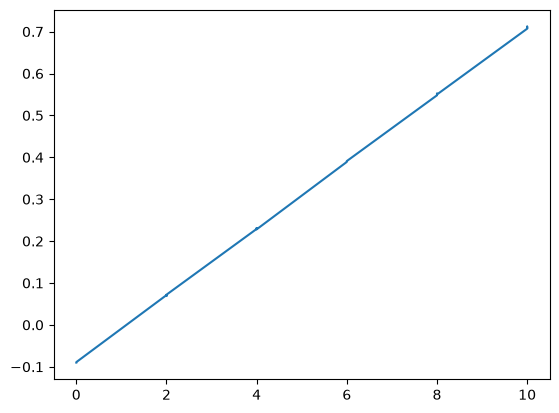

In [77]:
plt.plot(clean_data["concentration_uM"], clean_data["corrected_absorbance"])
plt.show()

<div class="oppgave">

**Prøv selv:** Plott gjennomsnittet for hver konsentrasjon med standardavviket som feilstolper. Bruk `summary` fra gruppene ovenfor og `plt.errorbar(x, y, yerr=..., fmt="o", capsize=4)`. Konsentrasjonene ligger i `summary.index`.

</div>

In [ ]:
plt.errorbar(??, ??, yerr=??, fmt="o", capsize=4)
plt.xlabel("Concentration (µmol/L)")
plt.ylabel("Absorbance")
plt.show()

<div class="diskuter">

**Diskuter:** Hvilken informasjon mister vi når vi plotter gjennomsnitt i stedet for alle replikatene? Hvorfor er det ikke nok å skrive «error bars» i figurteksten?

</div>

## En reproduserbar arbeidsflyt

<div class="viktig">

1. Les rådataene og ikke endre dem
2. Undersøk: `info()`, `isna().sum()`
3. Lag en arbeidskopi med `copy()`
4. Gjør begrunnede ryddevalg, for eksempel `dropna(subset=...)`
5. Lag nye kolonner i stedet for å overskrive målinger
6. Lagre resultatet i en **ny** fil

</div>

Koden dokumenterer *hva* vi har gjort. Vi må i tillegg kunne forklare *hvorfor* valgene er rimelige.

<div class="diskuter">

**Diskuter:** Syns du fordeler ved å bruke Pandas til dataanalyse veier opp det at du må lære deg en del for å bruke det?

</div>

__Oppgaver__:

<div class="bilde-hoyre" style="width:26%">

![Flammeprøver](bilder/flammeprøver.jpg)
<p class="kreditering"></p>

</div>

1. Les `reaction_kinetics.csv`, undersøk datatypene og sorter etter tid. Lag en ny kolonne `relative_absorbance` der hver absorbans deles på startverdien. Plott den relative absorbansen mot tid og beskriv utviklingen med kjemiske ord.
2. Fila `flame_emission.csv` inneholder emisjonsintensitet ved 589, 671 og 766 nm for prøver med Na⁺, Li⁺ og K⁺. Undersøk datasettet, og beregn gjennomsnittlig emisjon for hvert ion ved hver bølgelengde med `groupby`. Hvilket ion emitterer sterkest ved hver bølgelengde? Stemmer det med flammefargene du kjenner?
3. Plott alle kalibreringsstandardene med ulik markør for hver replikatserie. Blir figuren mer eller mindre informativ?
4. Lag en figur der en misvisende y-akse får to nesten like måleserier til å se svært forskjellige ut. Lag deretter en redelig versjon, og forklar valgene dine.
5. Skriv et fullstendig program som leser `uvvis_raw.csv`, undersøker manglende verdier, lager en arbeidskopi, fjerner den dokumenterte mislykkede målingen, blankkorrigerer og lagrer resultatet i en ny fil. Programmet skal aldri endre rådatafila.

Alle datafilene ligger i `../datahandtering_visualisering/data/`.